# Notes #

---

The density in the disk is prescribed by:
\begin{equation}
  \rho(r,\theta) = \rho_0 \left(\frac{r}{r_0}\right)^{-\alpha} \exp{\left(-\frac{\cos^2 \theta}{2\epsilon^2}\right)}
\end{equation}

The mass of the disk is then given by:
\begin{align}
  M_{\rm disc} & = \int_0^{2\pi}\!\int_{r_\min}^{r_\max}\!\int_{-z_\max}^{z_\max}\!\rho R\, dR\, dz\, d\phi ~ \mathrm{(ZRP)}= \int_0^{2\pi}\!\int_{r_\min}^{r_\max}\int_0^{\pi}\!\rho r^2 \sin \theta\, dr\, d\theta\, d\phi ~ \mathrm{(RTP)} \\
               & = 2\pi \rho_0 \int_{r_\min}^{r_\max}\! r^2 \left(\frac{r}{r_0}\right)^{-\alpha} dr \int_0^{\pi}\!\sin \theta \exp{\left(-\frac{\cos^2 \theta}{2\epsilon^2}\right)} d\theta \\
               & = 2\pi \rho_0 r_0^{\alpha} \frac{1}{(3-\alpha)} \left[r^{3-\alpha}\right]_{r_\min}^{r_\max} \left[-\sqrt{\frac{\pi}{2}} \epsilon ~ \mathrm{erf}\left(\frac{\cos\theta}{\sqrt{2}\epsilon}\right)\right]_0^{\pi} \\
               & =\left(2\pi\right)^{3/2} \rho_0 r_0^{\alpha} \epsilon \frac{1}{3-\alpha}\left(r_\max^{3-\alpha} - r_\min^{3-\alpha}\right) ~ \mathrm{erf}\left(\frac{1}{\sqrt{2}\epsilon} \right)\\
\end{align}

If one then sets the disc mass, $M_{\rm disc}$, the fiducial density factor, $\rho_0$, becomes known.

---

The Keplerian rotation period at cylindrical radius $R$ is given by:
\begin{equation}
  t_{\rm K} = \frac{2\pi}{\Omega_{\rm K}},
\end{equation}
where $\Omega_{\rm K} = \sqrt{GM_* / R^3}$.

For a central mass of $M_* = 1M_\odot$, and a radius of $R = 0.02$ au ($= r_\min$), one rotation is then $\simeq 8.926\times 10^4$ s.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib import cm
import dispatch
import dispatch.select
import itertools
import sys
import astropy.constants as cnst
from dispatch.graphics import curvilinear_transforms
from read_pebbles_dict import read_pebbles_dict

plt.interactive(True)
au = cnst.au.cgs.value

In [10]:
def patch_grid_edges(p, slicedir, scale_factor=1.0, truecoords=True):
    """
    Using the corners of the patch, create a matplotlib patch that draws
    the grid edges.

    """

    from matplotlib.patches import Rectangle, Wedge

    lo_corners = []
    hi_corners = []
    origin = p.llc_cart
    for o,s in zip(origin,p.size):
        lo_corners.append(o)
        hi_corners.append(o + s)
    active_corners = lo_corners, hi_corners

    if truecoords:
        if slicedir == 1:
            llx, urx = active_corners[0][1], active_corners[1][1]
            lly, ury = active_corners[0][2], active_corners[1][2]
        elif slicedir == 2:
            llx, urx = active_corners[0][0], active_corners[1][0]
            lly, ury = active_corners[0][2], active_corners[1][2]
        elif slicedir == 3:
            llx, urx = active_corners[0][0], active_corners[1][0]
            lly, ury = active_corners[0][1], active_corners[1][1]
    else:
        if slicedir == 1:
            llx, urx = p.llc_cart[1], p.llc_cart[1] + p.size[1]
            lly, ury = p.llc_cart[2], p.llc_cart[2] + p.size[2]
        elif slicedir == 2:
            llx, urx = p.llc_cart[0], p.llc_cart[0] + p.size[0]
            lly, ury = p.llc_cart[2], p.llc_cart[2] + p.size[2]
        elif slicedir == 3:
            llx, urx = p.llc_cart[0], p.llc_cart[0] + p.size[0]
            lly, ury = p.llc_cart[1], p.llc_cart[1] + p.size[1]

    if p.mesh_type == 'Cartesian' or truecoords: # Cartesian or Cartesian-like
        llx *= scale_factor
        urx *= scale_factor
        if p.mesh_type == 'Cartesian':
            lly *= scale_factor
            ury *= scale_factor
        edges = Rectangle((llx,lly),width=(urx-llx),height=(ury-lly),fc='none',lw=1.0,
                          ec='0.7',linestyle='dashed',zorder=0.01/min(p.ds)+0.1)
    elif p.mesh_type == 'spherical':
        # note that matplotlib sets theta=0 to what we typically consider to be theta=pi/2.
        thetamin = round(active_corners[0][1]*180.0/np.pi-90.0,3)
        thetamax = round(active_corners[1][1]*180.0/np.pi-90.0,3)
        llx, urx = active_corners[0][0], active_corners[1][0]
        if slicedir == 3 or slicedir == 2:
            llx *= scale_factor
            urx *= scale_factor
        edges = Wedge((0.0,0.0),urx,thetamin,thetamax,width=(urx-llx),fc='none',
                      lw=1.0,ec='k',linestyle='dotted',zorder=0.01/min(p.ds)+0.1)
    elif p.mesh_type == 'cylindrical':
        llx *= scale_factor
        urx *= scale_factor
        if slicedir == 3:
            lly *= scale_factor
            ury *= scale_factor
        # note that matplotlib sets theta=0 to what we typically consider to be theta=pi/2.
        phimin = round(active_corners[0][2]*180.0/np.pi-90.0,3)
        phimax = round(active_corners[1][2]*180.0/np.pi-90.0,3)
        llx, urx = active_corners[0][1], active_corners[1][1]
        edges = Wedge((p.position[0]*scale_factor,p.position[1]*scale_factor),urx,phimin,phimax,width=(urx-llx),fc='none',
                      lw=1.0,ec='k',linestyle='dotted',zorder=0.01/min(p.ds)+0.1)

    return edges

In [7]:
iout = 0
snap = dispatch.snapshot(iout=iout,data='../data')
print "No. patches:",len(snap.patches)
print "Domain size:",snap.patches[0].box
print "Patch size:",snap.patches[0].size
print "ID, time, nsteps, ntotcells, nghost, position, mesh type"
print "I/O format:", snap.patches[0].ioformat
for p in snap.patches:
    print "{:03d}".format(p.id),p.time,p.istep,p.gn,p.ng,p.position,p.mesh_type

No. patches: 50
Domain size: [1.4930080e+14 3.0787608e+00 1.0000000e+00]
Patch size: [1.49300800e+13 6.15752160e-01 6.28318531e+00]
ID, time, nsteps, ntotcells, nghost, position, mesh type
I/O format: 6
001 0.0 0 [37 47  1] [2 2 0] [7.76424000e+12 3.39292007e-01 0.00000000e+00] spherical
002 0.0 0 [37 47  1] [2 2 0] [2.26943200e+13 3.39292007e-01 0.00000000e+00] spherical
003 0.0 0 [37 47  1] [2 2 0] [3.76244000e+13 3.39292007e-01 0.00000000e+00] spherical
004 0.0 0 [37 47  1] [2 2 0] [5.25544800e+13 3.39292007e-01 0.00000000e+00] spherical
005 0.0 0 [37 47  1] [2 2 0] [6.74845600e+13 3.39292007e-01 0.00000000e+00] spherical
006 0.0 0 [37 47  1] [2 2 0] [8.24146400e+13 3.39292007e-01 0.00000000e+00] spherical
007 0.0 0 [37 47  1] [2 2 0] [9.73447200e+13 3.39292007e-01 0.00000000e+00] spherical
008 0.0 0 [37 47  1] [2 2 0] [1.12274800e+14 3.39292007e-01 0.00000000e+00] spherical
009 0.0 0 [37 47  1] [2 2 0] [1.27204880e+14 3.39292007e-01 0.00000000e+00] spherical
010 0.0 0 [37 47  1] [2

1 2 3 4 5 6 7 8 9 10 11

/usr/local/lib/python2.7/dist-packages/ipykernel_launcher.py:14: RuntimeWarning: divide by zero encountered in log10
  


 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50
min., max.: -inf -6.5803623


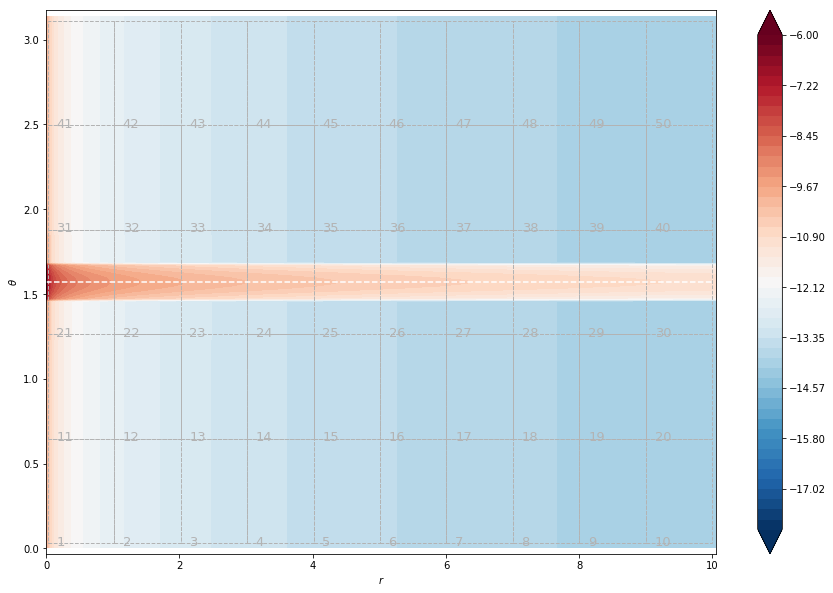

In [11]:
varidx = 'd'
truecoords = True
pvarlog = True
fig1 = plt.figure(figsize=(15.0,10.0))
fig1.clf()
cax = fig1.add_subplot(1,1,1)
cax.axis(xmin=0.0,xmax=10.05,ymin=-0.01*np.pi,ymax=1.01*np.pi)
gqmin, gqmax = 1.0e99, -1.0e99
pvmin, pvmax = -18.0, -6.0
levels = np.linspace(pvmin,pvmax,50)
for p in snap.patches:
    print p.id,
    var = p.var(varidx)
    if pvarlog: var = np.log10(p.var(varidx))
    gqmin = min(gqmin, np.nanmin(var))
    gqmax = max(gqmax, np.nanmax(var))
    plt.contourf(p.x/au,p.y,var.squeeze().T,levels,cmap=cm.RdBu_r,extend='both',zorder=0.0)
    edges = patch_grid_edges(p,3,truecoords=truecoords,scale_factor=1.0/au)
    cax.add_patch(edges)
    offset = [3*x for x in p.ng]
    offset[0] = 0
    gn_xpos = p.x[offset[1]]/au
    gn_ypos = p.y[offset[2]]
    cax.annotate(str(p.id),(gn_xpos,gn_ypos),color='0.7',fontsize=13,zorder=1.0,va='bottom')

cax.plot([0.0,10.0],[np.pi*0.5,np.pi*0.5],'w--')
cax.set_xlabel(r"$r$")
cax.set_ylabel(r"$\theta$")
plt.colorbar()
print
print "min., max.:",gqmin,gqmax

1 2 3 4 5 6 7 8 9 10

/usr/local/lib/python2.7/dist-packages/ipykernel_launcher.py:14: RuntimeWarning: divide by zero encountered in log10
  


 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50
min., max.: -inf -6.5803623


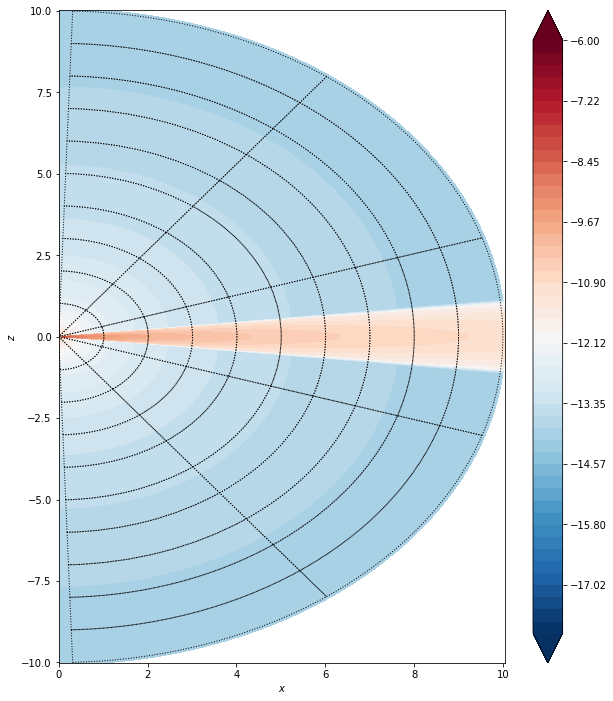

In [12]:
varidx = 'd'
truecoords = False
pvarlog = True
fig2 = plt.figure(figsize=(10.0,12.0))
fig2.clf()
cax = fig2.add_subplot(1,1,1)
cax.axis(xmin=0.0,xmax=10.05,ymin=-10.01,ymax=10.01)
gqmin, gqmax = 1.0e99, -1.0e99
pvmin, pvmax = -18.0, -6.0
levels = np.linspace(pvmin,pvmax,50)
for p in snap.patches:
    print p.id,
    var = p.var(varidx)
    if pvarlog: var = np.log10(p.var(varidx))
    gqmin = min(gqmin, np.nanmin(var))
    gqmax = max(gqmax, np.nanmax(var))
    # convert coords. from RTP to XYZ for pretty plotting
    x, y, z = curvilinear_transforms.rtp_to_xyz(p.x,p.y,p.z,phi_rotate=np.pi)
    plt.contourf(x.squeeze()/au,z.squeeze()/au,var.squeeze(),levels,cmap=cm.RdBu_r,extend='both',zorder=0.0)
    edges = patch_grid_edges(p,3,truecoords=truecoords,scale_factor=1.0/au)
    cax.add_patch(edges)
    #offset = [3*x for x in p.ng]
    #offset[0] = 0
    #gn_xpos = p.x[offset[1]]/au
    #gn_ypos = p.y[offset[2]]
    #cax.annotate(str(p.id),(gn_xpos,gn_ypos),color='0.7',fontsize=13,zorder=1.0,va='bottom')

cax.set_xlabel(r"$x$")
cax.set_ylabel(r"$z$")
plt.colorbar()
print
print "min., max.:",gqmin,gqmax

In [13]:
pebbles = None
for p in snap.patches:
    print p.id,
    pebbles = read_pebbles_dict(pebbles=pebbles,ip=p.id,it=iout,data='../data')

print
print "no. pebbles:",len(pebbles)
x, y = [], []
sizes = []
s_min, s_max = 1.0e99, -1.0e99
for peb in pebbles.itervalues():
    xx, yy, dummy = peb.p[0]
    x.append(xx)
    y.append(yy)
    ss = peb.s
    sizes.append(ss)
    s_min, s_max = min(s_min, peb.s), max(s_max, peb.s)

x = np.array(x)
y = np.array(y)
sizes = np.array(sizes)
print "Size min., max.:", s_min, s_max

1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50
no. pebbles: 56623
Size min., max.: 0.0010013162 0.9938455


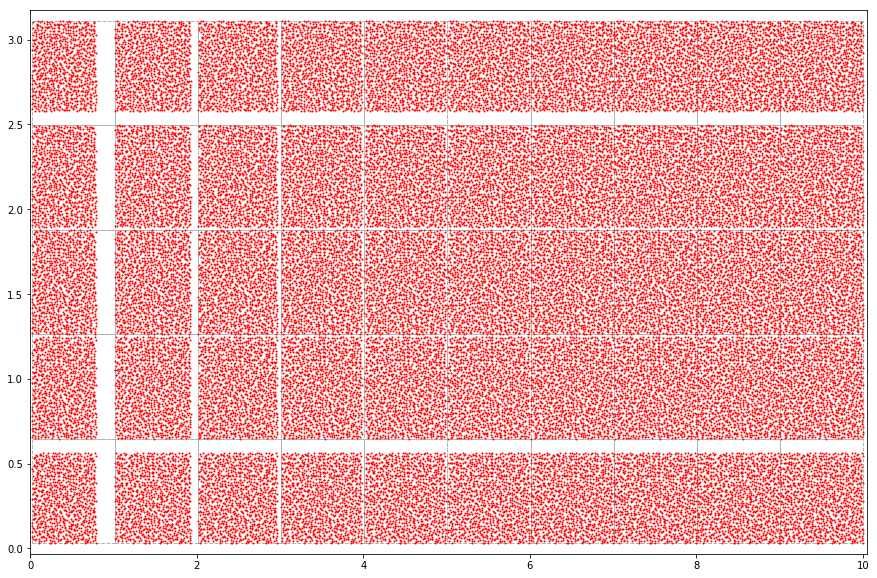

In [39]:
fig3 = plt.figure(figsize=(15.0,10.0))
fig3.clf()
cax = fig3.add_subplot(1,1,1)
cax.axis(xmin=0.0,xmax=10.05,ymin=-0.01*np.pi,ymax=1.01*np.pi)
cax.scatter(x/au,y,s=1.0,c='r',marker='o')
for p in snap.patches:
    edges = patch_grid_edges(p,3,truecoords=True,scale_factor=1.0/au)
    cax.add_patch(edges)

56623


Text(0,0.5,'$N$')

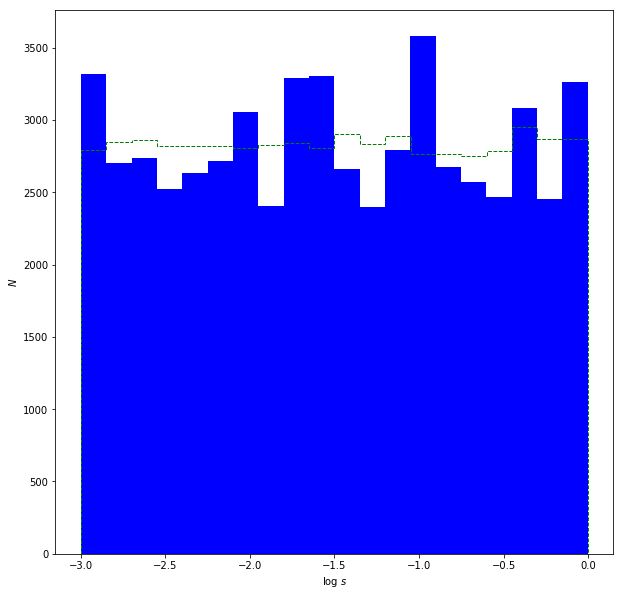

In [38]:
fig4 = plt.figure(figsize=(10.,10.))
fig4.clf()
cax = fig4.add_subplot(1,1,1)
print len(sizes)
n, bins, hist = cax.hist(np.log10(sizes),20,facecolor='blue',log=False)
log_size_rand = -3.0 * np.random.rand(len(sizes))
n, bins, hist = cax.hist(log_size_rand,20,histtype='step',color='g',linestyle='dashed')
cax.set_xlabel(r"log $s$")
cax.set_ylabel(r"$N$")